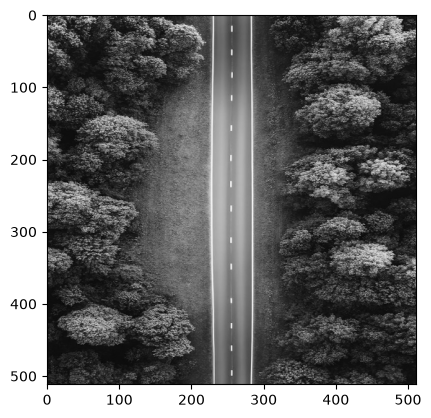

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('doroga.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.resize(image_gray, (512, 512)).astype(np.float32)

plt.imshow(image_gray, cmap="gray")
plt.show()

In [5]:
def haar_2d(img):
    rows, cols = img.shape
    
    row_avg = (img[:, 0::2] + img[:, 1::2]) / 2
    row_diff = (img[:, 0::2] - img[:, 1::2]) / 2
    
    LL = (row_avg[0::2, :] + row_avg[1::2, :]) / 2
    LH = (row_avg[0::2, :] - row_avg[1::2, :]) / 2   
    
    HL = (row_diff[0::2, :] + row_diff[1::2, :]) / 2 
    HH = (row_diff[0::2, :] - row_diff[1::2, :]) / 2
    
    return LL, LH, HL, HH

In [6]:
LL1, LH1, HL1, HH1 = haar_2d(image_gray)

print("LL1:", LL1.shape)
print("LH1:", LH1.shape)
print("HL1:", HL1.shape)
print("HH1:", HH1.shape)

LL1: (256, 256)
LH1: (256, 256)
HL1: (256, 256)
HH1: (256, 256)


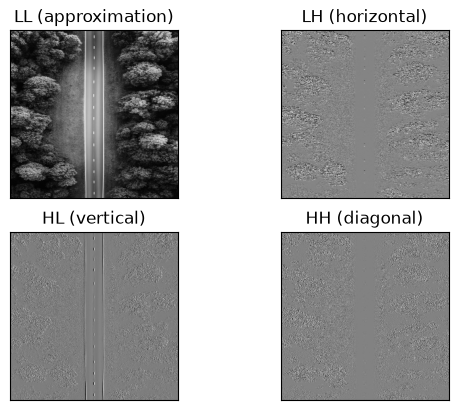

In [7]:
plt.subplot(221), plt.imshow(LL1, cmap="gray")
plt.title("LL (approximation)"), plt.xticks([]), plt.yticks([])

plt.subplot(222), plt.imshow(LH1, cmap="gray")
plt.title("LH (horizontal)"), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(HL1, cmap="gray")
plt.title("HL (vertical)"), plt.xticks([]), plt.yticks([])

plt.subplot(224), plt.imshow(HH1, cmap="gray")
plt.title("HH (diagonal)"), plt.xticks([]), plt.yticks([])

plt.show()

LL1: (256, 256)
LL2: (128, 128)
LL3: (64, 64)


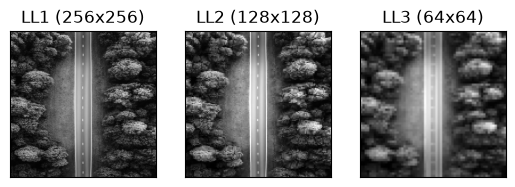

In [8]:
LL2, LH2, HL2, HH2 = haar_2d(LL1)

LL3, LH3, HL3, HH3 = haar_2d(LL2)

print("LL1:", LL1.shape)
print("LL2:", LL2.shape)
print("LL3:", LL3.shape)

plt.subplot(131), plt.imshow(LL1, cmap="gray")
plt.title("LL1 (256x256)"), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(LL2, cmap="gray")
plt.title("LL2 (128x128)"), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(LL3, cmap="gray")
plt.title("LL3 (64x64)"), plt.xticks([]), plt.yticks([])

plt.show()

In [9]:
print("Оригинал:", image_gray.size, "пикселей")
print("LL1:", LL1.size, "пикселей")
print("LL2:", LL2.size, "пикселей")
print("LL3:", LL3.size, "пикселей")
print("Сжатие:", image_gray.size / LL3.size, "раз")

Оригинал: 262144 пикселей
LL1: 65536 пикселей
LL2: 16384 пикселей
LL3: 4096 пикселей
Сжатие: 64.0 раз


In [11]:
threshold = 5

def compress(arr, th):
    return np.where(np.abs(arr) < th, 0, arr)

LH1_c = compress(LH1, threshold)
HL1_c = compress(HL1, threshold)
HH1_c = compress(HH1, threshold)

LH2_c = compress(LH2, threshold)
HL2_c = compress(HL2, threshold)
HH2_c = compress(HH2, threshold)

LH3_c = compress(LH3, threshold)
HL3_c = compress(HL3, threshold)
HH3_c = compress(HH3, threshold)

print("LH1: до", np.count_nonzero(LH1), "после", np.count_nonzero(LH1_c))
print("HL1: до", np.count_nonzero(HL1), "после", np.count_nonzero(HL1_c))
print("HH1: до", np.count_nonzero(HH1), "после", np.count_nonzero(HH1_c))

LH1: до 61277 после 30151
HL1: до 63253 после 24433
HH1: до 59554 после 22370


In [16]:
def haar_2d_inverse(LL, LH, HL, HH):

    row_avg = np.zeros((LL.shape[0] * 2, LL.shape[1]))
    row_avg[0::2, :] = LL + LH
    row_avg[1::2, :] = LL - LH
    
    row_diff = np.zeros((LH.shape[0] * 2, LH.shape[1]))
    row_diff[0::2, :] = HL + HH
    row_diff[1::2, :] = HL - HH
    
    img_reconstructed = np.zeros((LL.shape[0] * 2, LL.shape[1] * 2))
    img_reconstructed[:, 0::2] = row_avg + row_diff
    img_reconstructed[:, 1::2] = row_avg - row_diff
    
    return img_reconstructed

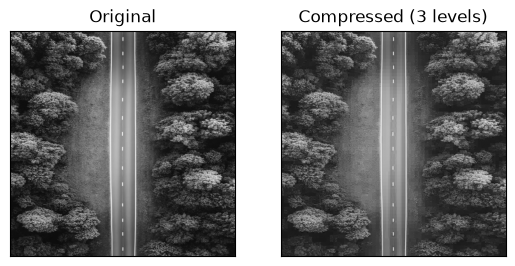

In [17]:
LL2_rec = haar_2d_inverse(LL3, LH3_c, HL3_c, HH3_c)

LL1_rec = haar_2d_inverse(LL2_rec, LH2_c, HL2_c, HH2_c)

img_rec = haar_2d_inverse(LL1_rec, LH1_c, HL1_c, HH1_c)

plt.subplot(121), plt.imshow(image_gray, cmap="gray")
plt.title("Original"), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(img_rec, cmap="gray")
plt.title("Compressed (3 levels)"), plt.xticks([]), plt.yticks([])

plt.show()

In [19]:
total_before = image_gray.size

total_after = (np.count_nonzero(LL3) + np.count_nonzero(LH3_c) + np.count_nonzero(HL3_c) + np.count_nonzero(HH3_c) + np.count_nonzero(LH2_c) + np.count_nonzero(HL2_c) + np.count_nonzero(HH2_c) + np.count_nonzero(LH1_c) + np.count_nonzero(HL1_c) + np.count_nonzero(HH1_c))

print("Коэффициентов до:", total_before)
print("Коэффициентов после:", total_after)
print("Сжатие:", total_before / total_after, "раз")

Коэффициентов до: 262144
Коэффициентов после: 101063
Сжатие: 2.59386719175168 раз


In [20]:
from skimage.metrics import structural_similarity, mean_squared_error

img_rec_norm = cv2.normalize(img_rec, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

mse = mean_squared_error(image_gray.astype(np.uint8), img_rec_norm)
ssim, _ = structural_similarity(image_gray.astype(np.uint8), img_rec_norm, full=True)

print("MSE:", mse)
print("SSIM:", ssim)

MSE: 45.063011169433594
SSIM: 0.9175940068320557


In [21]:
print("После обнуления мелких деталей изображение восстановлено.Качество чуть хуже, но структура сохранена")

После обнуления мелких деталей изображение восстановлено.Качество чуть хуже, но структура сохранена
